# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 30.09.2025

Мягкий дедлайн: 14.10.2025 23:59

Жесткий дедлайн: 18.10.2025 23:59


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `StochasticAverageGradient`
* `MomentumDescent`
* `Adam`

В файле `linear_regression.py` вам необходимо будет реализовать класс `LinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).

### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 11 баллов.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-02-gd-Username.ipynb**, где Username — ваша фамилия.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: ...

## Задание 1. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`.

**Все реализуемые методы должны быть векторизованы!**

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

### Градиент функции потерь MSE

На семинаре про [матрично-векторное дифференцирование](https://github.com/esokolov/ml-course-hse/blob/master/2025-fall/seminars/sem03-vector-diff.pdf) вы должны были обсуждать дифференцирование функции потерь MSE в матричном виде.

### Задание 1.0. Градиент MSE в матричном виде (0.02 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

Выпишите ниже (подсмотрев в семинар или решив самостоятельно) градиент для функции потерь MSE в матричном виде.

**Решение:**

2X^T(Xw - y)

### Задание 1.1. Learning Rate Schedules (0.03 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью него мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. Ваша задача в этом пункте – реализовать `TimeDecayLR`, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

**Обратите внимание**

Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

Чтобы это работало, уже на данном этапе должны быть реализованы в `linear_regression.py`:

* `compute_gradients(X, y)` для MSE (в дальнейшем, в Задании 7, сюда добавляется член L2-регуляризации),
* `compute_loss(X, y)` для MSE (аналогично с учётом L2 при необходимости).

Если идёте строго по порядку, реализуйте эти MSE-версии в начале Задания 2.1 (используя формулы из п. 1.0), а затем вернитесь к заданиям 1.2–1.6 - код оптимизаторов менять не придётся. В Задании 8 вы просто расширите обе функции под `LogCosh` и `Huber`, переключая их через `self.loss_function`.

Такой подход позволяет свободно менять функцию потерь, не переписывая алгоритмы оптимизации.

### Задание-примечание 1.1. Родительский класс BaseDescent (0 баллов).

В файле `descents.py` приведен шаблон класса `BaseDescent` – родительского класса для модификаций градиентного спуска, от которого будут наследоваться другие классы (`VanillaGradientDescent`, `StochasticGradientDescent`, `MomentumDescent` и `Adam`). Более подробно про наследование классов в Python можно прочитать
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html

В классе `BaseDescent` **все методы уже реализованы**. Цель этого задания – внимательно ознакомиться с тем, как устроен этот класс.

Обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма. Функция `update_weights` должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$

### Задание 1.2. Полный градиентный спуск VanillaGradientDescent (0.5 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 1.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 баллов).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 1.4 Stochastic Average Gradient (0.45 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индекс(ы) $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k, \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на одном (или нескольких) объекте за итерацию.

Реализуйте класс `SAG` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]`.


### Задание 1.5 Метод Momentum - MomentumDescent (0.8 баллов).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 1.6. Метод Adam (Adaptive Moment Estimation) (1.5 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 2. Линейная регресия (1 балл)

### Задание 2.1. Решение методом градиентного спуска (0.5 балла)

В этом задании вам предстоит написать свою реализацию линейной регресии, обучаемой с использованием градиентного спуска, с опорой на подготовленные шаблоны в файле `linear_regression.py` - **LinearRegressionModel**. По сути линейная регрессия будет оберткой, которая запускает обучение

Необходимо соблюдать следующие условия:

* Все вычисления должны быть векторизованы;
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `loss_history`, в нём будем хранить значения функции потерь до каждого шага, начиная с нулевого (до первого шага по антиградиенту) и значение функции потерь после оптимизации.

### Задание 2.2. Аналитическое решение (0.5 балла)

Но, как мы помним из лекции, помимо решения при помощи градиентного спуска, для ряда функций потерь можно выписать в том числе аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE. Выведите оптимальную формулу для $w$, держа в памяти формулу MSE, и дополните класс `LinearRegression`

$$\text{MSE} = \| X w - y \|^2$$
$$ w = $$

**Вопрос**: Как мы помним, у аналитического решения есть минусы, какие кстати?

**Ответ**:

Тут мы ничего специально проверять в контесте не будем


In [41]:
import importlib
import linear_regression

importlib.reload(linear_regression)
from linear_regression import LinearRegression

In [34]:
import numpy as np
from linear_regression import LinearRegression

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [35]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = LinearRegression(optimizer=None)
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.1013158237188696
Your MSE 0.1013158237188696


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [36]:
x[:, 3] = x[:, 2] + x[:, 4]

In [37]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = LinearRegression(optimizer=None)
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.10412990851964202
Your MSE 0.10412990851964202


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением, в нашем случае усеченным, чтобы было проще (это не то же самое, что обычный SVD, у него другие размерности матриц, смотрите ниже). Воспользуйтесь `scipy.sparse.linalg.svds` с числом компонент 4

Выведите формулу для w и снова дополните класс `LinearRegression`

$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$ w = $$

In [42]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = LinearRegression(optimizer="SVD")
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.10412990851964202
Your MSE 0.10412990851964199


## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `LinearRegression`. В начале мы сделаем небольшую локальную проверку на "адекватность" и "запускаемость" ваших моделей, после чего уже можно будет делать посылки в Яндекс Контест.

In [43]:
%load_ext autoreload

In [44]:
#%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

In [45]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [46]:
# Если вы реализовали не все методы спуска, то уберите лишние из списка ниже
descent_models = [
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
    optimizer = descent_model()
    model = LinearRegression(
        optimizer=optimizer,
        tolerance=tolerance,
        max_iter=max_iter,
    )
    model.fit(x, y)
    assert len(model.loss_history) == max_iter + 1, "Loss history failed"
    y_pred = model.predict(x)
    assert y_pred.shape == y.shape, "Prediction shape does not match target variable"

Если ваше решение прошло все тесты локально, то теперь пришло время протестировать его в [Яндекс Контесте](https://new.contest.yandex.ru/contests/82854/start).

Для каждой задачи из контеста вставьте ID успешной посылки и ваш ник (почту):

* **Ник/почта**:


* **VanillaGradientDescent**:


* **StochasticDescent**:


* **SAGDescent**:


* **MomentumDescent**:


* **Adam**:


* **LinearRegression**:

## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.
*
*

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [125]:
import numpy as np
import pandas as pd  # при желании, можете заменить на polars/pyspark или что угодно, что вам нравится

import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import LinearRegression

sns.set(style='darkgrid')

In [170]:
data = pd.read_csv('autos.csv')  # разумеется, если вы используете не pandas, это надо поменять

In [171]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное


<Axes: xlabel='log_price', ylabel='Count'>

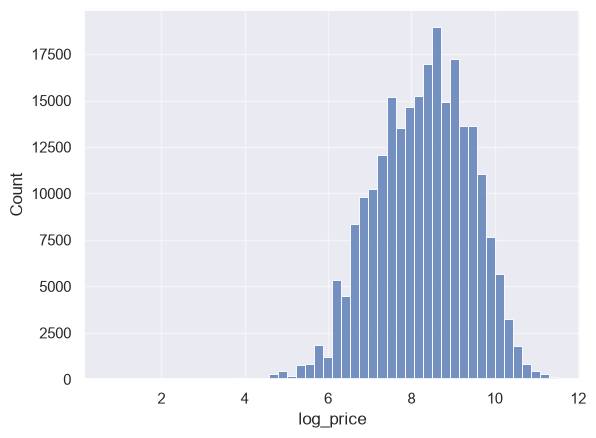

In [172]:
#sns.histplot(data, x='price', bins=50)
data['log_price'] = np.log(data['price'])

data = data[data['log_price'] > 0]
sns.histplot(data, x='log_price', bins=50)

In [173]:
categorical = list(data.select_dtypes(include=['object', 'category', 'string']).columns)

numeric = list(data.select_dtypes(include='number').columns)

other = list(data.select_dtypes(exclude=['object', 'category', 'string', 'number']).columns)

numeric = [
    col for col in numeric
    if col not in ['price', 'log_price']
]

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [174]:
data['bias'] = 1
other += ['bias']

x = data[categorical + numeric + other]
y = data['price']

In [165]:
data.isna().sum()
data['model'].nunique()

249

А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки:

In [175]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other',  'passthrough', other)
])

x = column_transformer.fit_transform(x)

In [167]:
# Разбиваем признаки и исходную цену на train/val/test (8:1:1).
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    x, np.asarray(y, dtype=float), test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1 / 0.9, random_state=41
)


## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)


Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [176]:
y_train = np.asarray(y_train, dtype=float)
y_val = np.asarray(y_val, dtype=float)
y_test = np.asarray(y_test, dtype=float)

In [215]:
descent_classes = [
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam,
]

lambdas = np.logspace(-2, 2, 20)
MSES = {}  # Валидационная MSE в квадрате единиц цены.
RMSES = {}  # Валидационная RMSE в исходных единицах цены.
best_models = {}  # Эти модели предсказывают логарифм цены.
best_lambdas = {}

for descent_class in descent_classes:
    name = descent_class.__name__
    min_mse = float("inf")
    best_model = None
    min_lambda = None

    for lmd in lambdas:
        optimizer = descent_class()
        optimizer.lr_schedule.lambda_ = lmd
        model = LinearRegression(optimizer=optimizer)

        try:
            # Слишком большие шаги могут привести к переполнению.
            # Такой запуск пропускаем, а не используем при выборе модели.
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                model.fit(X_train, y_train)
                pred = model.predict(X_val)
                val_mse = float(np.mean((pred - y_val) ** 2))
        except FloatingPointError:
            continue

        if not np.isfinite(val_mse):
            continue
        if val_mse < min_mse:
            min_mse = val_mse
            min_lambda = lmd
            best_model = model

    if best_model is None:
        print(f"{name}: ни одного успешного значения lambda_")
        continue

    # Сохраняем именно выбранную модель без повторного случайного обучения.
    best_models[name] = best_model
    best_lambdas[name] = min_lambda
    MSES[name] = best_model.compute_loss(X_test, y_test)
    RMSES[name] = float(np.sqrt(MSES[name]))

    print(
        f"{name}: lambda_={min_lambda:.6g}, "
        f"test MSE={MSES[name]:.4f}, val RMSE={RMSES[name]:.4f}"
    )


VanillaGradientDescent: lambda_=1.27427, test MSE=18771834.7678, val RMSE=4332.6475
StochasticGradientDescent: lambda_=0.297635, test MSE=22468718.5537, val RMSE=4740.1180
SAGDescent: lambda_=37.9269, test MSE=28804860.3324, val RMSE=5367.0160
MomentumDescent: lambda_=2.06914, test MSE=17609068.2014, val RMSE=4196.3160
Adam: lambda_=100, test MSE=18701305.1735, val RMSE=4324.5006


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

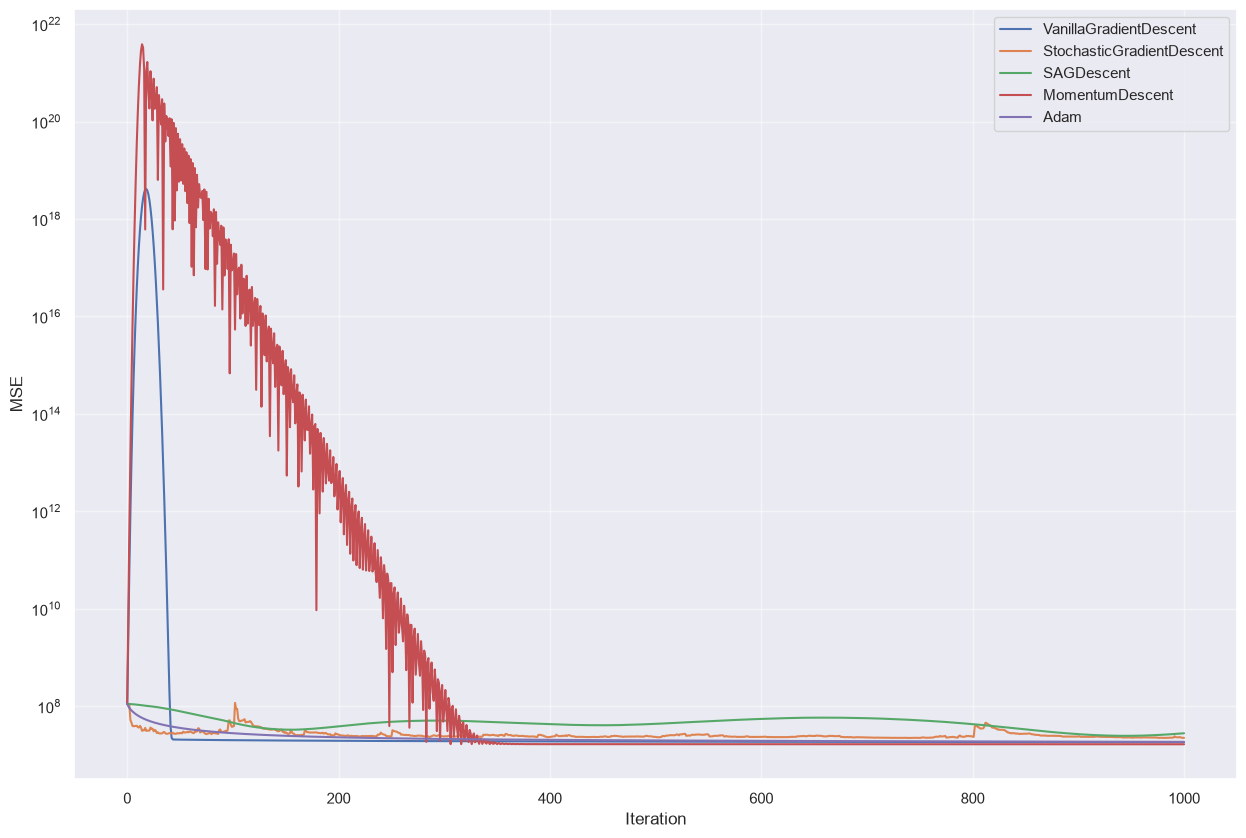

In [184]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 10))

for name, model in best_models.items():
    plt.plot(model.loss_history, label=name)


plt.xlabel('Iteration')
plt.ylabel('MSE')
plt.legend()
plt.yscale('log')
plt.show()

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

10 1000 20633034.101875987 достигнут лимит
10 1000 20844198.5182867 достигнут лимит
10 1000 20637714.432134446 достигнут лимит
10 1000 20592291.14688425 достигнут лимит
10 1000 20297387.91941101 достигнут лимит
10 1000 20510812.837004077 достигнут лимит
10 1000 20271786.7885579 достигнут лимит
10 1000 20339708.920855556 достигнут лимит
10 1000 20561660.804772846 достигнут лимит
10 1000 20660700.627415802 достигнут лимит
200 1000 20285199.346840452 достигнут лимит
200 1000 20236586.393004023 достигнут лимит
200 1000 20167871.674056314 достигнут лимит
200 1000 20276464.36221511 достигнут лимит
200 1000 20344868.57152091 достигнут лимит
200 1000 20306261.328144524 достигнут лимит
200 1000 20327784.48965159 достигнут лимит
200 1000 20268394.177780215 достигнут лимит
200 1000 20280334.0512168 достигнут лимит
200 1000 20292086.461420447 достигнут лимит


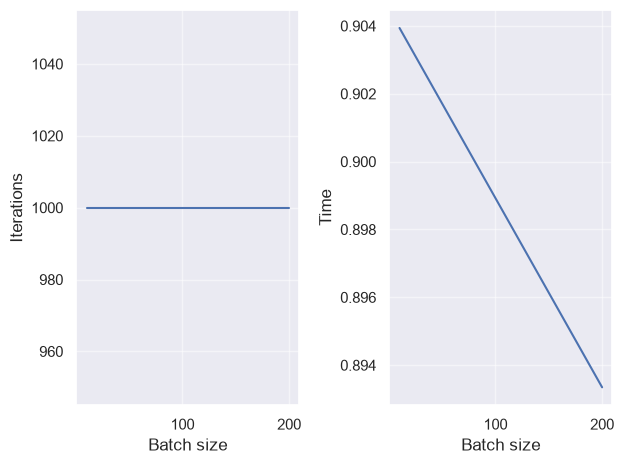

In [192]:
from time import perf_counter

k = 10
sizes = [10, 200]
timesForBatch = []
itersForBatch = []

for batch_size in sizes:
    meanTime = 0
    meanIters = 0
    for i in range(k):
        optimizer = StochasticGradientDescent(batch_size=batch_size)
        optimizer.lr_schedule.lambda_ = best_lambdas['StochasticGradientDescent']
        model = LinearRegression(optimizer=optimizer, max_iter=1000, tolerance=1e-3)

        start = perf_counter()
        model.fit(X_train, y_train)
        elapsed = perf_counter() - start
        finite = np.isfinite(model.w).all()

        if not finite:
            reason = "численная ошибка"
        elif optimizer.iteration < model.max_iter:
            reason = "критерий маленького шага"
        else:
            reason = "достигнут лимит"

        print(
            batch_size,
            optimizer.iteration,
            model.compute_loss(X_val, y_val),
            reason
        )

        meanIters += optimizer.iteration
        meanTime += elapsed

    timesForBatch.append(meanTime / k)
    itersForBatch.append(meanIters / k)

fig, axs = plt.subplots(nrows=1, ncols=2)

axs[0].plot(sizes, itersForBatch)
axs[0].set(xlabel='Batch size', ylabel='Iterations')

axs[1].plot(sizes, timesForBatch)
axs[1].set(xlabel='Batch size', ylabel='Time')

plt.tight_layout()
plt.show()

**Выводы:**

`### Ваши выводы ###`

## Задание 7. Регуляризация (0.5 балл)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [206]:
descent_classes = [
    #VanillaGradientDescent,
    #StochasticGradientDescent,
    #SAGDescent,
    MomentumDescent,
    Adam,
]

lambdas = np.logspace(-1, 3, 10)
mus = np.logspace(-10, -8, 10)
REGMSES = {}
REGRMSES = {}
REG_best_models = {}
REG_best_lambdas_mus = {}

for descent_class in descent_classes:
    name = descent_class.__name__
    min_mse = float("inf")
    best_model = None
    min_lambda = None
    min_mu = None

    for lmd in lambdas:
        for mu in mus:
            optimizer = descent_class()
            optimizer.lr_schedule.lambda_ = lmd
            model = LinearRegression(optimizer=optimizer, l2_coef=mu/2)

            try:
                # Слишком большие шаги могут привести к переполнению.
                # Такой запуск пропускаем, а не используем при выборе модели.
                with np.errstate(over="raise", invalid="raise", divide="raise"):
                    model.fit(X_train, y_train)
                    pred = model.predict(X_val)
                    val_mse = float(np.mean((pred - y_val) ** 2))
            except FloatingPointError:
                continue

            if not np.isfinite(val_mse):
                continue
            if val_mse < min_mse:
                min_mse = val_mse
                min_lambda = lmd
                min_mu = mu
                best_model = model

    if best_model is None:
        print(f"{name}: ни одного успешного значения lambda_")
        continue

    # Сохраняем именно выбранную модель без повторного случайного обучения.
    REG_best_models[name] = best_model
    REG_best_lambdas_mus[name] = [min_lambda, min_mu]
    test_pred = best_model.predict(X_test)
    REGMSES[name] = float(np.mean((test_pred - y_test) ** 2))
    REGRMSES[name] = float(np.sqrt(REGMSES[name]))

    print(
        f"{name}: lambda_={min_lambda:.6g}, mu={min_mu:.6g}, "
        f"test MSE={REGMSES[name]:.4f}, val RMSE={REGRMSES[name]:.4f}"
    )

from sklearn.metrics import r2_score

R2 = {}
for dclass in descent_classes:
    name = dclass.__name__
    R2[name] = [r2_score(y_train, REG_best_models[name].predict(X_train)), r2_score(y_test, REG_best_models[name].predict(X_test))]
    print(
        f"{name}: R2_train = {R2[name][0]:.4f}, "
        f"R2_test = {R2[name][1]:.4f}"
    )



MomentumDescent: lambda_=2.15443, mu=1e-08, test MSE=17651211.8866, val RMSE=4201.3345
Adam: lambda_=1000, mu=1e-08, test MSE=17581930.7779, val RMSE=4193.0813
MomentumDescent: R2_train = 0.7414, R2_test = 0.7338
Adam: R2_train = 0.7428, R2_test = 0.7349


VanillaGradientDescent: lambda_=1.6681, test MSE=19675673.5124, val RMSE=4435.7269
StochasticGradientDescent: lambda_=0.0774264, test MSE=23314144.3712, val RMSE=4828.4723
SAGDescent: lambda_=35.9381, test MSE=26168851.5901, val RMSE=5115.5500
MomentumDescent: lambda_=1.6681, test MSE=19363899.4975, val RMSE=4400.4431
Adam: lambda_=100, test MSE=20347488.0090, val RMSE=4510.8190
VanillaGradientDescent: R2_train = 0.7073, R2_test = 0.7033
StochasticGradientDescent: R2_train = 0.6526, R2_test = 0.6484
SAGDescent: R2_train = 0.6070, R2_test = 0.6054
MomentumDescent: R2_train = 0.7123, R2_test = 0.7080
Adam: R2_train = 0.6976, R2_test = 0.6932

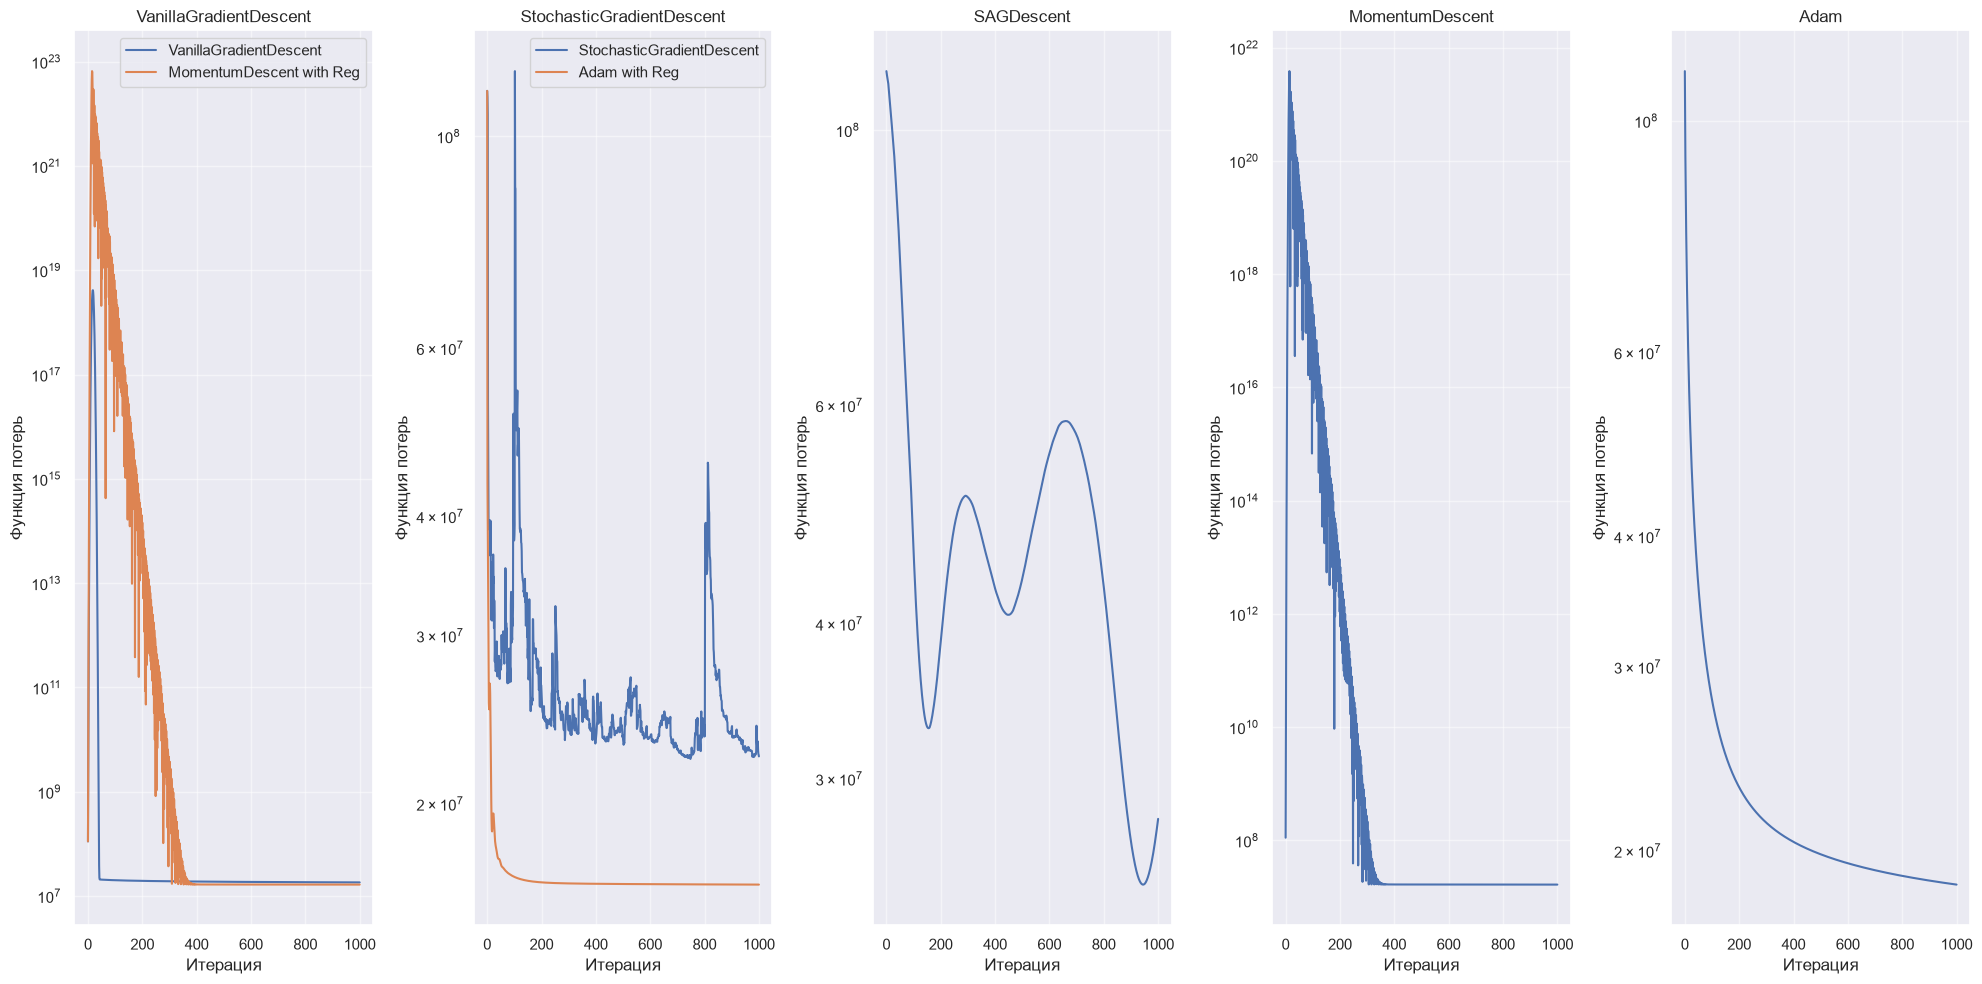

In [207]:
fig, axs = plt.subplots(nrows=1, ncols=5, figsize=(20, 10))

for i, (name, model) in enumerate(best_models.items()):
    axs[i].plot(model.loss_history, label=name)
    axs[i].set_title(name)
    axs[i].set_xlabel('Итерация')
    axs[i].set_ylabel('Функция потерь')
    axs[i].set_yscale('log')

for i, (name, model) in enumerate(REG_best_models.items()):
    axs[i].plot(model.loss_history, label=name+" with Reg")
    axs[i].legend()

plt.tight_layout()
plt.show()

**Вывод:**

`### Ваши выводы ###`

## Задание 8. Альтернативные функции потерь (1 балл)


В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:


**Решение:**

`### Ваше решение тут ###`

In [216]:
import importlib
import linear_regression

importlib.reload(linear_regression)

from linear_regression import LinearRegression, LossFunction

In [217]:
from linear_regression import LossFunction
descent_classes = [
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam,
]

lambdas = np.logspace(-2, 2, 20)
HuberMSES = {}
HuberRMSES = {}
Huber_best_models = {}
Huber_best_lambdas = {}

for descent_class in descent_classes:
    name = descent_class.__name__
    min_mse = float("inf")
    best_model = None
    min_lambda = None

    for lmd in lambdas:
        optimizer = descent_class()
        optimizer.lr_schedule.lambda_ = lmd
        model = LinearRegression(optimizer=optimizer, loss_function=LossFunction.Huber)

        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                model.fit(X_train, y_train)
                pred = model.predict(X_val)
                val_mse = float(np.mean((pred - y_val) ** 2))
        except FloatingPointError:
            continue

        if not np.isfinite(val_mse):
            continue
        if val_mse < min_mse:
            min_mse = val_mse
            min_lambda = lmd
            best_model = model

    if best_model is None:
        print(f"{name}: ни одного успешного значения lambda_")
        continue

    Huber_best_models[name] = best_model
    Huber_best_lambdas[name] = min_lambda
    test_pred = best_model.predict(X_test)
    HuberMSES[name] = float(np.mean((test_pred - y_test) ** 2))
    HuberRMSES[name] = float(np.sqrt(HuberMSES[name]))

    print(
        f"{name}: lambda_={min_lambda:.6g}, "
        f"test MSE={HuberMSES[name]:.4f}, test RMSE={HuberRMSES[name]:.4f}"
    )


VanillaGradientDescent: lambda_=100, test MSE=24209608.2090, test RMSE=4920.3260
StochasticGradientDescent: lambda_=61.5848, test MSE=26390458.8691, test RMSE=5137.1645
SAGDescent: lambda_=100, test MSE=51022823.0594, test RMSE=7143.0262
MomentumDescent: lambda_=100, test MSE=20649672.1245, test RMSE=4544.1910
Adam: lambda_=100, test MSE=21709410.9811, test RMSE=4659.3359


In [218]:
from linear_regression import LossFunction

descent_classes = [
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam,
]

lambdas = np.logspace(2, 4, 15)
LogCoshMSES = {}
LogCoshRMSES = {}
LogCosh_best_models = {}
LogCosh_best_lambdas = {}

for descent_class in descent_classes:
    name = descent_class.__name__
    min_mse = float("inf")
    best_model = None
    min_lambda = None

    for lmd in lambdas:
        optimizer = descent_class()
        optimizer.lr_schedule.lambda_ = lmd
        model = LinearRegression(optimizer=optimizer, loss_function=LossFunction.LogCosh)

        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                model.fit(X_train, y_train)
                pred = model.predict(X_val)
                val_mse = float(np.mean((pred - y_val) ** 2))
        except FloatingPointError:
            continue

        if not np.isfinite(val_mse):
            continue
        if val_mse < min_mse:
            min_mse = val_mse
            min_lambda = lmd
            best_model = model

    if best_model is None:
        print(f"{name}: ни одного успешного значения lambda_")
        continue

    LogCosh_best_models[name] = best_model
    LogCosh_best_lambdas[name] = min_lambda
    test_pred = best_model.predict(X_test)
    LogCoshMSES[name] = float(np.mean((test_pred - y_test) ** 2))
    LogCoshRMSES[name] = float(np.sqrt(LogCoshMSES[name]))

    print(
        f"{name}: lambda_={min_lambda:.6g}, "
        f"test MSE={LogCoshMSES[name]:.4f}, test RMSE={LogCoshRMSES[name]:.4f}"
    )


VanillaGradientDescent: lambda_=10000, test MSE=24212567.4627, test RMSE=4920.6267
StochasticGradientDescent: lambda_=7196.86, test MSE=23285097.1873, test RMSE=4825.4634
SAGDescent: lambda_=10000, test MSE=51086042.5776, test RMSE=7147.4501
MomentumDescent: lambda_=10000, test MSE=20648925.3902, test RMSE=4544.1089
Adam: lambda_=7196.86, test MSE=20247586.3160, test RMSE=4499.7318


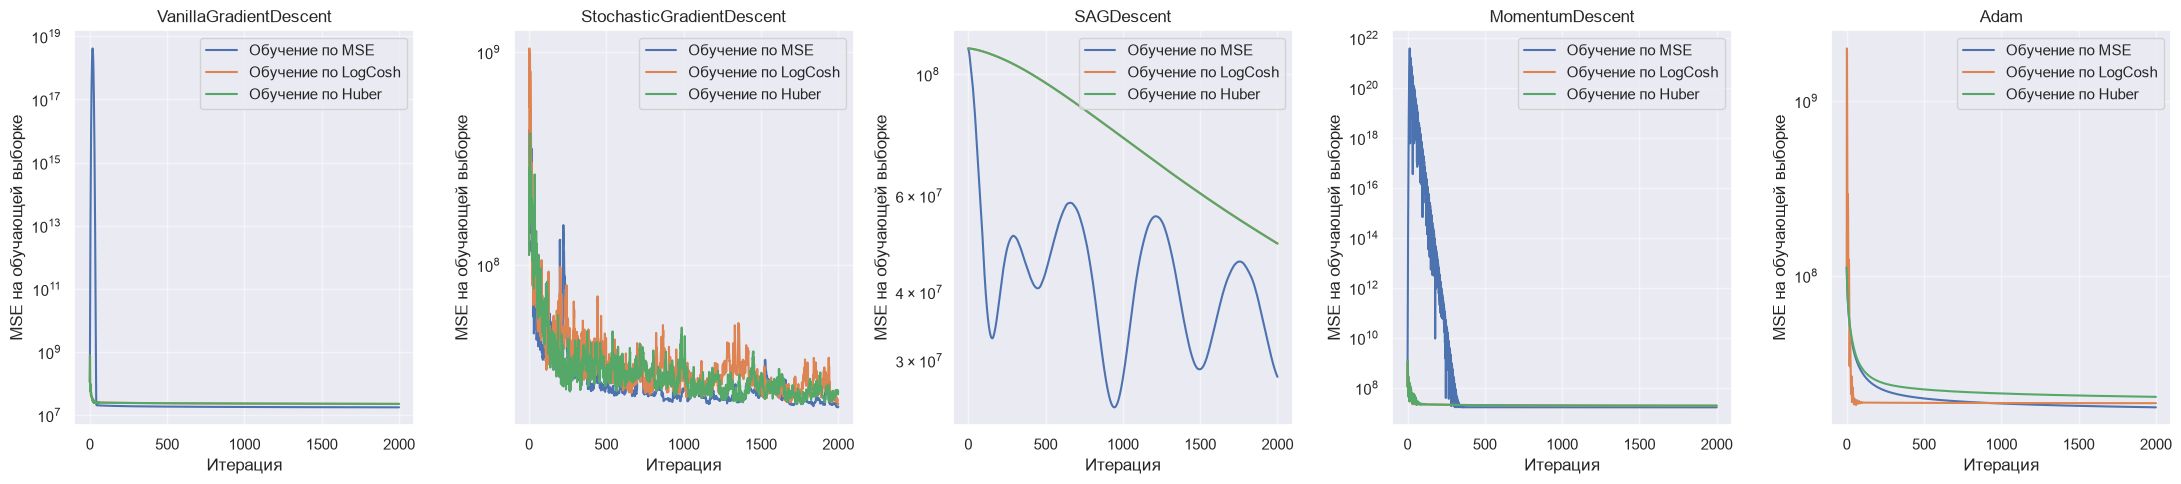

In [219]:
groups = [
    ("Обучение по MSE", best_models),
    ("Обучение по LogCosh", LogCosh_best_models),
    ("Обучение по Huber", Huber_best_models),
]

for loss_name, models in groups:
    for name, model in models.items():
        if not getattr(model, "mse_history", None):
            raise ValueError(
                f"{name} ({loss_name}): нет истории MSE. "
                "Перезагрузите linear_regression и заново обучите модели."
            )

fig, axs = plt.subplots(1, 5, figsize=(22, 5))

for ax, name in zip(axs, best_models):
    for loss_name, models in groups:
        if name in models:
            ax.plot(models[name].mse_history, label=loss_name)

    ax.set_title(name)
    ax.set_xlabel("Итерация")
    ax.set_ylabel("MSE на обучающей выборке")
    ax.set_yscale("log")
    ax.legend()

plt.tight_layout()
plt.show()


Программно реализуйте градиентный спуск с данными функциями потерь в файле `descents.py`, обучите все пять методов (без регуляризации) аналогично 5 заданию, сравните их качество с пятью методами из 5 задания.



Пример того, как можно запрограммировать использование нескольких функций потерь внутри одного класса градиентного спуска:


```python
from enum import auto
from enum import Enum

import numpy as np

class LossFunction(Enum):
    MSE = auto()
    MAE = auto()
    LogCosh = auto()
    Huber = auto()

...
class LinearRegression:
    def __init__(
        self,
        optimizer: BaseDescent,
        l2_coef: float = 0.0,
        tolerance: float = 1e-6,
        max_iter: int = 1000,
        loss_function: LossFunction = LossFunction.MSE
    ):
        ...
    
    def compute_gradients(self, X: np.ndarray, y: np.ndarray) -> np.ndarray:
        if self.loss_function is LossFunction.MSE:
            # YOUR CODE FOR MSE
        if self.loss_function is LossFunction.MAE:
            # YOUR CODE FOR MAE
        ...
    
    def compute_loss(self, X: np.ndarray, y: np.ndarray) -> float:
        if self.loss_function is LossFunction.MSE:
            # YOUR CODE FOR MSE
        if self.loss_function is LossFunction.MAE:
            # YOUR CODE FOR MAE
        ...
...

```

### Кулинарно-социализационный бонус. (0.5 балла)

Как мы знаем, осень прекрасная пора, время пробовать новое и делиться теплом с друзьями и близкими. Выберите рецепт, который соответствует вашему настроению, приготовьте выбранное блюдо и угостите хотя бы одного человека им. Кратко опишите ваши впечатления, прикрепите рецепт и фотографии блюда и довольного гостя.

### Бонус Бонусный со звездочкой. Рефакторинг LinearRegression с соблюдением OCP (0.5 балла)

Этот бонус для тех, у кого нет друзей и кулинарных способностей.

Цель - провести рефакторинг класса `LinearRegression`, руководствуясь принципом **Open-Closed Principle** (OCP). Напомним его суть: программные сущности (классы, модули, функции) должны быть открыты для расширения, но закрыты для модификации. В нашем контексте это означает, что добавление новой функции потерь или нового типа регуляризации не должно требовать внесения изменений в уже существующий код модели `LinearRegression` или оптимизаторов.

Вам предоставляется свобода в выборе конкретной реализации (например, через `Strategy`/`Protocol`/интерфейсы), однако итоговое решение должно удовлетворять перечисленным ниже требованиям.

**Требования к реализации**

**1. Совместимость с существующим кодом (жёсткие требования):**

* Публичный API класса `LinearRegression` должен остаться неизменным, чтобы не нарушать работу автоматических тестов.
* Аргумент конструктора `loss_function: LossFunction = LossFunction.MSE` и сам `Enum` `LossFunction` сохраняются.
* Имена/сигнатуры ключевых методов (`predict`, `compute_gradients`, `compute_loss`, `fit`) и полей (`w`, `loss_history`) должны остаться прежними.
* Должно работать динамическое переключение лосса через enum: присваивание
`model.loss_function = LossFunction.Huber` меняет поведение `compute_loss/compute_gradients` без пересоздания модели.
* Код оптимизаторов из `descents.py` не меняется и по-прежнему вызывает только `self.model.compute_gradients(...)`.

**2. Расширяемость архитектуры:**

* Необходимо реализовать возможность инъекции кастомной стратегии для функции потерь (например, через новый необязательный аргумент в конструкторе `loss=...`). При передаче такой стратегии она должна использоваться вместо той, что выбирается через `Enum`.
* Добавьте поддержку L2-регуляризации. Её реализация и способ интеграции остаются на ваше усмотрение. Решение о штрафовании свободного члена (`bias`) примите самостоятельно и кратко опишите в ноутбуке.


Для зачёта задания предоставьте в конце ноутбука отдельный раздел, в котором содержатся:

* Короткое описание (2–5 предложений), как решение следует OCP.
* Две мини-демонстрации:
    1.  Создание модели с `loss_function=LogCosh`, вызов `compute_loss`, последующее присваивание `model.loss_function = LossFunction.MSE` и повторный вызов `compute_loss`, показывающий, что поведение модели изменилось.
    2.  Создание модели с передачей вашей кастомной стратегии в конструктор и демонстрация того, что она корректно работает со стандартным оптимизатором (например, `Adam`).
* Подтверждение, что базовый сценарий (только `enum`, без кастомных стратегий) проходит ваши локальные проверки.